# Household Energy Prediction Using Linear Regression

## Objective
Predict hourly household energy consumption (`Total_Energy`) using
Linear Regression and compare two prepared datasets.

## Datasets
- **Model A:** Dataset prepared for Model A during feature engineering and PCA.
- **Model B:** Dataset prepared for Model B during feature engineering and PCA.

Both datasets will be analysed in this notebook, with separate models
and results.

## Mathematical Model
Linear Regression predicts energy consumption as:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \cdots + \beta_p x_p
$$

where:
- $\hat{y}$ is predicted hourly energy consumption in Wh.
- $\beta_0$ is the intercept.
- $\beta_j$ is the coefficient of input feature $x_j$.
- $p$ is the number of input features.

The model learns coefficients by minimising the sum of squared errors:

$$
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

## Evaluation
We will preserve chronological order when splitting the data and compare
both models using MAE, RMSE, and R² on the same evaluation timestamps.

In [21]:
# Data handling and numerical operations
import pandas as pd
import numpy as np
from pathlib import Path

# Visualisation
import matplotlib.pyplot as plt

# Linear Regression
from sklearn.linear_model import LinearRegression

# Time-ordered cross-validation
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso

In [5]:
df_A = pd.read_csv(data_folder / "energy_model_A_pca11.csv")
df_B = pd.read_csv(data_folder / "energy_model_B_pca6_calendar.csv")

print("Model A shape:", df_A.shape)
print("Model A columns:", df_A.columns.tolist())
display(df_A.head())

print("Model B shape:", df_B.shape)
print("Model B columns:", df_B.columns.tolist())
display(df_B.head())

Model A shape: (3289, 14)
Model A columns: ['date', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'Total_Energy', 'split']


,date,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,Total_Energy,split
0,2016-01-11 17:00:00,5.110123,1.400306,-0.727908,-0.288922,-1.660293,1.723690,0.153982,-1.227327,-1.108349,-0.197960,0.775331,540,train
1,2016-01-11 18:00:00,5.093709,1.255047,-0.645525,-0.060188,-1.921390,0.655241,-0.143542,-1.387939,-1.002338,-0.038749,0.686973,1370,train
2,2016-01-11 19:00:00,5.703124,2.641273,-0.466049,0.341102,-1.732885,0.508668,-0.237793,-1.192641,-2.147870,-0.750999,0.301881,1190,train
3,2016-01-11 20:00:00,5.363267,2.699256,0.061216,1.835086,-1.645020,0.551409,1.138031,-1.231681,-1.244798,-0.418894,0.246485,960,train
4,2016-01-11 21:00:00,4.532671,2.561363,0.192938,1.772744,-1.557283,0.699563,0.570903,-1.148758,-0.840036,-0.178371,0.370830,760,train


Model B shape: (3289, 18)
Model B columns: ['date', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'hour_sin', 'hour_cos', 'is_weekend', 'is_afternoon_peak', 'month_2', 'month_3', 'month_4', 'month_5', 'Weekend_Afternoon', 'Total_Energy', 'split']


,date,PC1,PC2,PC3,PC4,PC5,PC6,hour_sin,hour_cos,is_weekend,is_afternoon_peak,month_2,month_3,month_4,month_5,Weekend_Afternoon,Total_Energy,split
0,2016-01-11 17:00:00,-2.385360,1.332462,-0.822393,0.229846,0.179091,-0.308249,-0.965926,-2.588190e-01,0,1,0,0,0,0,0,540,train
1,2016-01-11 18:00:00,-2.389230,1.254058,-0.803186,0.132570,0.137984,-0.281298,-1.000000,-1.836970e-16,0,1,0,0,0,0,0,1370,train
2,2016-01-11 19:00:00,-2.475669,2.257678,-0.787061,-0.109231,0.748326,-0.734700,-0.965926,2.588190e-01,0,0,0,0,0,0,0,1190,train
3,2016-01-11 20:00:00,-2.323473,2.501608,-0.720584,-0.667954,0.243962,-0.106355,-0.866025,5.000000e-01,0,0,0,0,0,0,0,960,train
4,2016-01-11 21:00:00,-1.883592,2.138435,-0.463353,-0.658371,0.053692,-0.082442,-0.707107,7.071068e-01,0,0,0,0,0,0,0,760,train


## Step 3: Verify Dataset Alignment and Existing Splits

Both models must use the same observations and data partitions for a
fair comparison.

Check:
- Matching timestamps, target values, and split labels.
- Number of observations and date range in each split.
- Missing values.

In [6]:
# Convert timestamps and arrange both datasets chronologically
for df in (df_A, df_B):
    df["date"] = pd.to_datetime(df["date"])
    df.sort_values("date", inplace=True)
    df.reset_index(drop=True, inplace=True)

# Verify that both datasets describe the same observations
alignment_columns = ["date", "Total_Energy", "split"]

assert df_A[alignment_columns].equals(df_B[alignment_columns]), (
    "Model A and Model B have different timestamps, targets, or splits."
)

print("Alignment verified: timestamps, targets, and splits match.")

# Inspect existing partitions
display(
    df_A.groupby("split")
    .agg(
        rows=("date", "size"),
        start_date=("date", "min"),
        end_date=("date", "max")
    )
    .sort_values("start_date")
)

print("Missing values — Model A:", df_A.isna().sum().sum())
print("Missing values — Model B:", df_B.isna().sum().sum())

Alignment verified: timestamps, targets, and splits match.


C:\Users\Admin\AppData\Local\Temp\ipykernel_13976\2157725874.py:4: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("date", inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_13976\2157725874.py:5: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_13976\2157725874.py:4: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("date", inplace=True)
C:\Users\A

,rows,start_date,end_date
split,,,
train,2631,2016-01-11 17:00:00,2016-04-30 07:00:00
test,658,2016-04-30 08:00:00,2016-05-27 17:00:00


Missing values — Model A: 0
Missing values — Model B: 0


In [7]:
df_A["date"] = pd.to_datetime(df_A["date"])
df_B["date"] = pd.to_datetime(df_B["date"])

df_A = df_A.sort_values("date").reset_index(drop=True)
df_B = df_B.sort_values("date").reset_index(drop=True)

In [8]:
# Columns that must not be used as predictors
exclude_columns = ["date", "Total_Energy", "split"]

# Model A
X_train_A = df_A.loc[df_A["split"] == "train"].drop(columns=exclude_columns)
X_test_A = df_A.loc[df_A["split"] == "test"].drop(columns=exclude_columns)

y_train_A = df_A.loc[df_A["split"] == "train", "Total_Energy"]
y_test_A = df_A.loc[df_A["split"] == "test", "Total_Energy"]

# Model B
X_train_B = df_B.loc[df_B["split"] == "train"].drop(columns=exclude_columns)
X_test_B = df_B.loc[df_B["split"] == "test"].drop(columns=exclude_columns)

y_train_B = df_B.loc[df_B["split"] == "train", "Total_Energy"]
y_test_B = df_B.loc[df_B["split"] == "test", "Total_Energy"]

display(pd.DataFrame({
    "Model": ["A", "B"],
    "Training rows": [len(X_train_A), len(X_train_B)],
    "Testing rows": [len(X_test_A), len(X_test_B)],
    "Input features": [X_train_A.shape[1], X_train_B.shape[1]]
}))

,Model,Training rows,Testing rows,Input features
0,A,2631,658,11
1,B,2631,658,15


In [9]:
# Train Model A
lr_A = LinearRegression()
lr_A.fit(X_train_A, y_train_A)

# Train Model B
lr_B = LinearRegression()
lr_B.fit(X_train_B, y_train_B)

# Inspect fitted model properties
display(pd.DataFrame({
    "Model": ["A", "B"],
    "Intercept (Wh)": [lr_A.intercept_, lr_B.intercept_],
    "Number of coefficients": [len(lr_A.coef_), len(lr_B.coef_)],
    "Training matrix rank": [lr_A.rank_, lr_B.rank_]
}))

,Model,Intercept (Wh),Number of coefficients,Training matrix rank
0,A,613.968073,11,11
1,B,577.014936,15,14


## Step 6: Evaluate Linear Regression — Chronological Split

Compare Model A and Model B using training and testing predictions.

Metrics:
- MAE: Mean absolute prediction error in Wh.
- RMSE: Gives greater weight to large errors, measured in Wh.
- R²: Measures performance relative to predicting the evaluation set mean.

Compare training and testing performance to assess generalisation.

In [11]:
# Generate predictions
y_train_pred_A = lr_A.predict(X_train_A)
y_test_pred_A = lr_A.predict(X_test_A)

y_train_pred_B = lr_B.predict(X_train_B)
y_test_pred_B = lr_B.predict(X_test_B)

# Calculate evaluation metrics
evaluation_rows = []

for model_name, partition, actual, predicted in [
    ("A", "Train", y_train_A, y_train_pred_A),
    ("A", "Test", y_test_A, y_test_pred_A),
    ("B", "Train", y_train_B, y_train_pred_B),
    ("B", "Test", y_test_B, y_test_pred_B)
]:
    evaluation_rows.append({
        "Model": model_name,
        "Partition": partition,
        "MAE (Wh)": mean_absolute_error(actual, predicted),
        "RMSE (Wh)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    })

lr_chronological_results = pd.DataFrame(evaluation_rows)
display(lr_chronological_results.round(3))

,Model,Partition,MAE (Wh),RMSE (Wh),R²
0,A,Train,314.443,469.349,0.169
1,A,Test,272.022,395.884,0.138
2,B,Train,293.335,450.067,0.236
3,B,Test,283.288,403.487,0.104


## Step 7: Tune Polynomial Ridge Regression

Test whether nonlinear relationships improve energy predictions.

Hyperparameters:
- degree: 1 keeps linear features; 2 adds squared terms and interactions.
- alpha: Controls regularisation; larger values penalise large coefficients more.

Use five expanding chronological validation folds within the training
period. Select settings using the lowest mean validation RMSE.

The test set is reserved for the next evaluation step.

In [13]:
# Expanding chronological validation
time_cv = TimeSeriesSplit(n_splits=5)

# Compare linear and quadratic relationships
parameter_grid = {
    "poly__degree": [1, 2],
    "ridge__alpha": [0.1, 1, 10, 100, 1000, 10000]
}

tuned_models = {}
tuning_rows = []

for model_name, X_train, y_train in [
    ("A", X_train_A, y_train_A),
    ("B", X_train_B, y_train_B)
]:
    pipeline = Pipeline([
        ("poly", PolynomialFeatures(include_bias=False)),
        ("scale", StandardScaler()),
        ("ridge", Ridge())
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="neg_root_mean_squared_error",
        cv=time_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)
    tuned_models[model_name] = search

    tuning_rows.append({
        "Model": model_name,
        "Best degree": search.best_params_["poly__degree"],
        "Best alpha": search.best_params_["ridge__alpha"],
        "Mean CV RMSE (Wh)": -search.best_score_
    })

tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results.round(3))

,Model,Best degree,Best alpha,Mean CV RMSE (Wh)
0,A,1,100,463.113
1,B,2,1000,441.332


In [14]:
# GridSearchCV already refitted each selected model on all training rows
tuned_test_pred_A = tuned_models["A"].predict(X_test_A)
tuned_test_pred_B = tuned_models["B"].predict(X_test_B)

# Original Linear Regression test results
baseline_results = lr_chronological_results.loc[
    lr_chronological_results["Partition"] == "Test",
    ["Model", "MAE (Wh)", "RMSE (Wh)", "R²"]
].copy()

baseline_results["Method"] = "Linear Regression"

# Tuned Polynomial Ridge test results
tuned_rows = []

for model_name, actual, predicted in [
    ("A", y_test_A, tuned_test_pred_A),
    ("B", y_test_B, tuned_test_pred_B)
]:
    tuned_rows.append({
        "Model": model_name,
        "Method": "Tuned Polynomial Ridge",
        "MAE (Wh)": mean_absolute_error(actual, predicted),
        "RMSE (Wh)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    })

chronological_comparison = pd.concat(
    [baseline_results, pd.DataFrame(tuned_rows)],
    ignore_index=True
)

chronological_comparison = chronological_comparison[
    ["Model", "Method", "MAE (Wh)", "RMSE (Wh)", "R²"]
].sort_values(["Model", "Method"]).reset_index(drop=True)

display(chronological_comparison.round(3))

,Model,Method,MAE (Wh),RMSE (Wh),R²
0,A,Linear Regression,272.022,395.884,0.138
1,A,Tuned Polynomial Ridge,270.970,395.387,0.140
2,B,Linear Regression,283.288,403.487,0.104
3,B,Tuned Polynomial Ridge,303.364,400.801,0.116


## Kernel PCA and Cluster Feature Experiment

Load the dataset containing six kernel components, nine calendar
features, and five cluster indicators.

Verify alignment with the existing Model B observations before comparing
regression with and without cluster indicators.

In [15]:
df_B_cluster = pd.read_csv(
    data_folder / "energy_model_B_kpca6_calendar_clusters.csv",
    parse_dates=["date"]
)

df_B_cluster = df_B_cluster.sort_values("date").reset_index(drop=True)

# Verify matching observations, targets, and partitions
reference = df_B[["date", "Total_Energy", "split"]].copy()
reference["date"] = pd.to_datetime(reference["date"])
reference = reference.sort_values("date").reset_index(drop=True)

assert df_B_cluster[["date", "Total_Energy", "split"]].equals(
    reference
), "The new dataset does not align with Model B."

print("Alignment verified.")
print("Dataset shape:", df_B_cluster.shape)
display(df_B_cluster["split"].value_counts())

Alignment verified.
Dataset shape: (3289, 23)


split
train    2631
test      658
Name: count, dtype: int64

## Compare Linear Regression With and Without Cluster Features

Use identical chronological training and testing observations.

Compare:
1. Kernel PCA + calendar features.
2. Kernel PCA + calendar features + cluster indicators.

Evaluate both models using MAE, RMSE, and R² on the test period.

In [17]:
# Identify feature groups
cluster_columns = [
    column for column in df_B_cluster.columns
    if column.startswith("Cluster_")
]

base_columns = [
    column for column in df_B_cluster.columns
    if column not in ["date", "Total_Energy", "split"] + cluster_columns
]

# Existing chronological split
train_mask = df_B_cluster["split"].eq("train")
test_mask = df_B_cluster["split"].eq("test")

y_train_cluster = df_B_cluster.loc[train_mask, "Total_Energy"]
y_test_cluster = df_B_cluster.loc[test_mask, "Total_Energy"]

cluster_regression_models = {}
cluster_comparison_rows = []

for experiment, feature_columns in [
    ("Kernel PCA + calendar", base_columns),
    ("Kernel PCA + calendar + clusters", base_columns + cluster_columns)
]:
    X_train = df_B_cluster.loc[train_mask, feature_columns]
    X_test = df_B_cluster.loc[test_mask, feature_columns]

    model = LinearRegression()
    model.fit(X_train, y_train_cluster)

    predictions = model.predict(X_test)
    cluster_regression_models[experiment] = model

    cluster_comparison_rows.append({
        "Experiment": experiment,
        "Features": len(feature_columns),
        "Test MAE (Wh)": mean_absolute_error(
            y_test_cluster, predictions
        ),
        "Test RMSE (Wh)": np.sqrt(
            mean_squared_error(y_test_cluster, predictions)
        ),
        "Test R²": r2_score(y_test_cluster, predictions)
    })

cluster_prediction_comparison = pd.DataFrame(cluster_comparison_rows)
display(cluster_prediction_comparison.round(3))

,Experiment,Features,Test MAE (Wh),Test RMSE (Wh),Test R²
0,Kernel PCA + calendar,15,287.161,407.442,0.087
1,Kernel PCA + calendar + clusters,20,324.337,426.915,-0.003


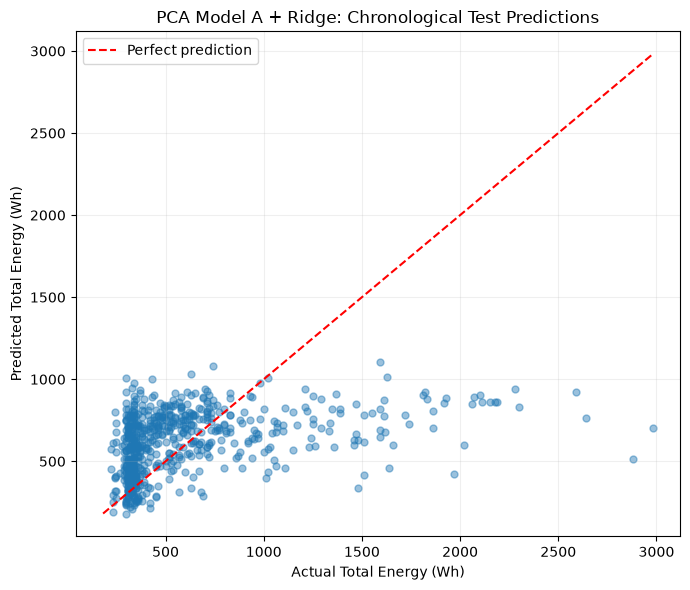

In [18]:
# Predictions from the selected PCA Model A Ridge model
pca_A_predictions = tuned_models["A"].predict(X_test_A)

plot_min = min(y_test_A.min(), pca_A_predictions.min())
plot_max = max(y_test_A.max(), pca_A_predictions.max())

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test_A,
    pca_A_predictions,
    alpha=0.45,
    s=25
)

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Total Energy (Wh)")
plt.ylabel("Predicted Total Energy (Wh)")
plt.title("PCA Model A + Ridge: Chronological Test Predictions")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

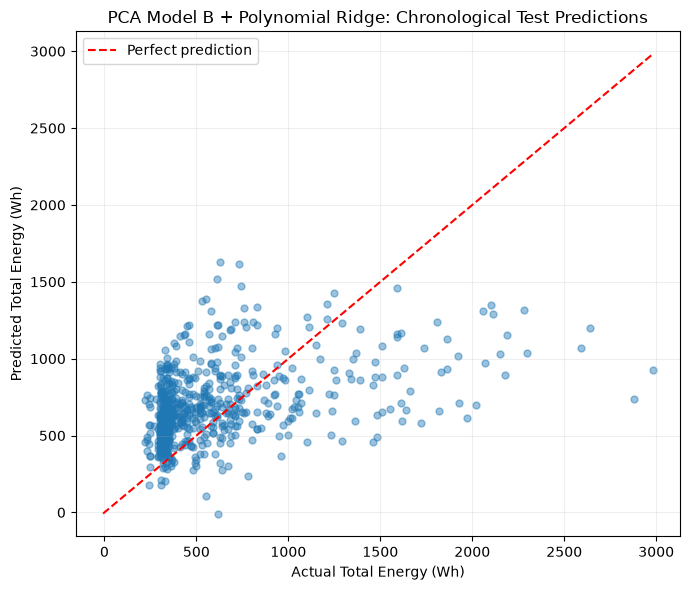

In [19]:
# Predictions from the selected PCA Model B model
pca_B_predictions = tuned_models["B"].predict(X_test_B)

plot_min = min(y_test_B.min(), pca_B_predictions.min())
plot_max = max(y_test_B.max(), pca_B_predictions.max())

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test_B,
    pca_B_predictions,
    alpha=0.45,
    s=25
)

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Total Energy (Wh)")
plt.ylabel("Predicted Total Energy (Wh)")
plt.title("PCA Model B + Polynomial Ridge: Chronological Test Predictions")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Tune Polynomial Lasso Regression — Chronological Split

Compare degrees 1 and 2 with different Lasso regularisation strengths
for Model A and Model B.

Use five expanding chronological validation folds within training data.
Select settings using mean validation RMSE.

Preserve the Ridge results for comparison.

In [22]:
lasso_parameter_grid = {
    "poly__degree": [1, 2],
    "lasso__alpha": [0.1, 1, 10, 100, 1000]
}

lasso_models = {}
lasso_tuning_rows = []

for model_name, X_train, y_train in [
    ("A", X_train_A, y_train_A),
    ("B", X_train_B, y_train_B)
]:
    lasso_pipeline = Pipeline([
        ("poly", PolynomialFeatures(include_bias=False)),
        ("scale", StandardScaler()),
        ("lasso", Lasso(max_iter=100000, tol=1e-4))
    ])

    lasso_search = GridSearchCV(
        estimator=lasso_pipeline,
        param_grid=lasso_parameter_grid,
        scoring="neg_root_mean_squared_error",
        cv=TimeSeriesSplit(n_splits=5),
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    lasso_search.fit(X_train, y_train)
    lasso_models[model_name] = lasso_search

    fitted_lasso = lasso_search.best_estimator_.named_steps["lasso"]

    lasso_tuning_rows.append({
        "Model": model_name,
        "Best degree": lasso_search.best_params_["poly__degree"],
        "Best alpha": lasso_search.best_params_["lasso__alpha"],
        "Mean CV RMSE (Wh)": -lasso_search.best_score_,
        "Nonzero coefficients": np.count_nonzero(fitted_lasso.coef_),
        "Total coefficients": fitted_lasso.coef_.size
    })

lasso_tuning_results = pd.DataFrame(lasso_tuning_rows)
display(lasso_tuning_results.round(3))

,Model,Best degree,Best alpha,Mean CV RMSE (Wh),Nonzero coefficients,Total coefficients
0,A,1,1,465.075,11,11
1,B,1,10,441.811,9,15


## Evaluate Lasso Against Ridge

Compare the selected Lasso and Ridge models on identical chronological
test observations using MAE, RMSE, and R².

Hyperparameters were selected using training-period validation.

In [23]:
regularisation_rows = []

for model_name, X_test, y_test in [
    ("A", X_test_A, y_test_A),
    ("B", X_test_B, y_test_B)
]:
    for method, search in [
        ("Ridge", tuned_models[model_name]),
        ("Lasso", lasso_models[model_name])
    ]:
        predictions = search.predict(X_test)

        regularisation_rows.append({
            "Model": model_name,
            "Method": method,
            "Degree": search.best_params_["poly__degree"],
            "Test MAE (Wh)": mean_absolute_error(y_test, predictions),
            "Test RMSE (Wh)": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "Test R²": r2_score(y_test, predictions)
        })

regularisation_comparison = pd.DataFrame(regularisation_rows)
display(regularisation_comparison.round(3))

,Model,Method,Degree,Test MAE (Wh),Test RMSE (Wh),Test R²
0,A,Ridge,1,270.970,395.387,0.140
1,A,Lasso,1,271.220,395.639,0.139
2,B,Ridge,2,303.364,400.801,0.116
3,B,Lasso,1,277.798,395.442,0.140


In [24]:
polynomial_lr_models = {}
polynomial_lr_cv_rows = []

for model_name, X_train, y_train in [
    ("A", X_train_A, y_train_A),
    ("B", X_train_B, y_train_B)
]:
    pipeline = Pipeline([
        ("poly", PolynomialFeatures(include_bias=False)),
        ("scale", StandardScaler()),
        ("linear", LinearRegression())
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"poly__degree": [1, 2, 3]},
        scoring="neg_root_mean_squared_error",
        cv=TimeSeriesSplit(n_splits=5),
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)
    polynomial_lr_models[model_name] = search

    # Show validation performance for every tested degree
    for params, mean_score, std_score in zip(
        search.cv_results_["params"],
        search.cv_results_["mean_test_score"],
        search.cv_results_["std_test_score"]
    ):
        polynomial_lr_cv_rows.append({
            "Model": model_name,
            "Degree": params["poly__degree"],
            "Mean CV RMSE (Wh)": -mean_score,
            "CV RMSE std (Wh)": std_score,
            "Selected": (
                params["poly__degree"]
                == search.best_params_["poly__degree"]
            )
        })

polynomial_lr_cv_results = pd.DataFrame(polynomial_lr_cv_rows)
display(polynomial_lr_cv_results.round(3))

,Model,Degree,Mean CV RMSE (Wh),CV RMSE std (Wh),Selected
0,A,1,465.446,33.751,True
1,A,2,1135.284,1269.777,False
2,A,3,12798.620,21390.832,False
3,B,1,445.236,30.184,True
4,B,2,649.208,133.316,False
5,B,3,5653.443,2521.447,False


In [25]:
polynomial_lr_test_rows = []

for model_name, X_test, y_test in [
    ("A", X_test_A, y_test_A),
    ("B", X_test_B, y_test_B)
]:
    search = polynomial_lr_models[model_name]
    predictions = search.predict(X_test)

    polynomial_lr_test_rows.append({
        "Model": model_name,
        "Selected degree": search.best_params_["poly__degree"],
        "Test MAE (Wh)": mean_absolute_error(y_test, predictions),
        "Test RMSE (Wh)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Test R²": r2_score(y_test, predictions)
    })

polynomial_lr_test_results = pd.DataFrame(polynomial_lr_test_rows)
display(polynomial_lr_test_results.round(3))

,Model,Selected degree,Test MAE (Wh),Test RMSE (Wh),Test R²
0,A,1,272.022,395.884,0.138
1,B,1,283.288,403.487,0.104
